# Partie 4 — Système hybride à rejet de l'inconnu (*open-set recognition*)

## Objectif et cadrage
En conditions réelles, le diagnostic recevra forcément des entrées **jamais vues à l'entraînement** : une maladie absente du jeu de données, une feuille d'une autre plante, ou une photo qui n'est même pas une feuille. Un classifieur fermé est *obligé* de répondre l'une de ses classes connues — parfois avec grande confiance **à tort**. C'est le problème de la **reconnaissance en ensemble ouvert** (*open-set*) : le bon comportement n'est pas de deviner mais de **rejeter** l'entrée et de la signaler (« à faire examiner par un expert »).

## Deux signaux complémentaires
On combine les deux familles de modèles des parties précédentes, qui regardent l'entrée sous deux angles :
- **MSP** (*Maximum Softmax Probability*) — signal **discriminatif** (classifieur P2) : confiance max du *softmax*. Sur une entrée inconnue, le classifieur est souvent moins sûr → MSP basse → rejet.
- **Erreur de reconstruction de l'auto-encodeur** — signal **génératif** (AE P3 entraîné sur feuilles saines) : une entrée atypique se reconstruit mal → erreur haute → rejet.

Hypothèse de travail : ces deux signaux se **trompent sur des cas différents**, donc les combiner devrait rejeter plus d'inconnu que chacun seul. Toute la P4 consiste à **tester puis corriger** cette hypothèse avec des données.

## Protocole : *leave-one-class-out*
On retire **une** maladie M de l'entraînement (elle devient « l'inconnu »), on entraîne un classifieur sur les **9 classes restantes**, puis on mesure la capacité de chaque méthode à **rejeter M** au test — sans l'avoir jamais vue. On évalue enfin sur deux jeux hors-distribution (OOD) de difficulté croissante : feuilles d'autres espèces (proche) et photos non-feuille (lointain).

> **Règle d'or :** tous les seuils sont calés sur le **connu de validation** (budget 5 % de faux rejet). Le **test** n'est touché qu'une fois, pour les chiffres finaux.

In [ ]:
import os, json, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import torch.optim as optim
from sklearn.metrics import f1_score, accuracy_score
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights

## Cellule 1 — Configuration et rechargement du protocole figé
On ne recrée rien : on **recharge** le travail des parties précédentes pour garantir la cohérence du projet.
- `set_seed(42)` + `cudnn.deterministic` : reproductibilité (règle transverse, pénalité sinon).
- **Google Drive** : seul stockage persistant (les sessions Colab T4 gratuites se coupent).
- **kagglehub** (`emmarex/plantdisease`) : cache éphémère, mais `split.csv` (découpage anti-fuite 70/15/15 seed 42) fixe *exactement* quelle image va où → le découpage ne bouge pas entre sessions.
- **ae_cfg** chargé depuis `ae_config.json` (sauvegardé en P3) : config du meilleur AE (débruiteur k=64, seuil p95) + son poids `ae_k64_dn_best.pt` — on ne recrée rien à la main.
- Constantes héritées : **160 px + norm ImageNet** (clf, P2), **64 px + pixels [0,1]** (AE, P3) — conventions non négociables.

In [ ]:
# ============================================================
# PARTIE 4 — Système hybride avec rejet de l'inconnu
# Cellule 1 : Setup
# ============================================================


# --- Reproductibilité (règle transverse du projet) ---
def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# --- Drive (livrables persistants) ---
from google.colab import drive
drive.mount('/content/drive')

ROOT    = "/content/drive/MyDrive/Project_clean"
DATA    = os.path.join(ROOT, "data")
MODELS  = os.path.join(ROOT, "models")
RESULTS = os.path.join(ROOT, "results")
for d in (DATA, MODELS, RESULTS): os.makedirs(d, exist_ok=True)

# --- Données (cache éphémère kagglehub) ---
import kagglehub
DATA_ROOT = os.path.join(kagglehub.dataset_download("emmarex/plantdisease"), "PlantVillage")
print("DATA_ROOT:", DATA_ROOT)

# --- Constantes (reprises telles quelles de P2 / P3) ---
IMG_SIZE_CLF  = 160                       # transfer learning (P2)
IMG_SIZE_AE   = 64                        # auto-encodeur (P3)
IMAGENET_MEAN = [0.485, 0.456, 0.406]     # le clf attend la norm ImageNet
IMAGENET_STD  = [0.229, 0.224, 0.225]
NUM_WORKERS   = 2

# --- On recharge le protocole figé ---
split = pd.read_csv(os.path.join(DATA, "split.csv"))

#config de l’AE retenu, chargée depuis P3
AE_WEIGHTS = os.path.join(MODELS, "ae_k64_dn_best.pt")
with open(os.path.join(MODELS, "ae_config.json")) as f:
    ae_cfg = json.load(f)
ae_cfg["threshold_p95"] = ae_cfg["seuil_p95"]

assert os.path.exists(AE_WEIGHTS), f"introuvable : {AE_WEIGHTS}"
print("AE weights :", AE_WEIGHTS)
print("ae_cfg     :", ae_cfg)
print("splits     :", split["split"].value_counts().to_dict())

device: cuda
Mounted at /content/drive
Using Colab cache for faster access to the 'plantdisease' dataset.
DATA_ROOT: /kaggle/input/plantdisease/PlantVillage
AE weights : /content/drive/MyDrive/Project_clean/models/ae_k64_dn_best.pt
ae_cfg     : {'best_name': 'k64_dn', 'k': 64, 'denoising': True, 'noise_std': 0.1, 'seuil_p95': 0.011146215721964836, 'auroc_test': 0.6145647898382295, 'threshold_p95': 0.011146215721964836}
splits     : {'train': 11197, 'test': 2400, 'val': 2400}


## Cellule 2 — *Leave-one-class-out* : M = mildiou (*Tomato_Late_blight*)
**Pourquoi le mildiou comme inconnu ?** Choix réaliste *et* exigeant :
- maladie **majeure et répandue** de la tomate → cas crédible d'« émergence » qu'un système déployé rencontrerait ;
- **visuellement proche de l'alternariose** (*Early_blight*) — la confusion Early ↔ Late était l'erreur n°1 de la P1 → scénario de rejet **le plus dur**, donc le plus informatif ;
- classe **assez fournie** pour un échantillon de test de M exploitable.

**Ce que fait la cellule :** séparation `known` (9 classes) / `unknown` (M), puis **réindexation des 9 connues en 0..8** (on ne réutilise pas `class_idx`, qui référait aux 10 classes — sinon trou d'indice et fuite logique). Construction des **5 populations** + deux `assert` **anti-fuite** (M ni à l'entraînement ni en val connue).

In [ ]:
# ============================================================
# Cellule 2 — Leave-one-class-out : M = Late_blight
# ============================================================
M = "Tomato_Late_blight"
assert M in split["label"].unique(), "nom de M incorrect !"

# connu / inconnu
known   = split[split["label"] != M].copy()    # les 9 classes gardées
unknown = split[split["label"] == M].copy()     # le mildiou = inconnu

# 9 classes connues -> indices 0..8 (on RÉINDEXE, on ne réutilise pas class_idx)
known_classes = sorted(known["label"].unique())
cls_to_idx = {c: i for i, c in enumerate(known_classes)}
idx_to_cls = {i: c for c, i in cls_to_idx.items()}
NUM_KNOWN  = len(known_classes)

# les 5 populations de la P4
clf_train = known[known["split"] == "train"].copy()   # entraînement (M absent)
clf_val   = known[known["split"] == "val"].copy()      # val connus  -> calage τ
clf_test  = known[known["split"] == "test"].copy()     # test connus -> éval finale
unk_val   = unknown[unknown["split"] == "val"].copy()  # M en val    -> diagnostic
unk_test  = unknown[unknown["split"] == "test"].copy() # M en test   -> éval rejet

# garde-fous anti-fuite
assert M not in clf_train["label"].unique(), "FUITE : M à l'entraînement !"
assert M not in clf_val["label"].unique(),   "FUITE : M en val connue !"

print("M (inconnu) :", M)
print(f"{NUM_KNOWN} classes connues :")
for c in known_classes: print("   ", cls_to_idx[c], c)
print("\n--- Populations ---")
for name, d in [("train (connu)", clf_train), ("val (connu)", clf_val),
                ("test (connu)", clf_test), ("val (M)", unk_val), ("test (M)", unk_test)]:
    print(f"{name:16s}: {len(d):6d}")

M (inconnu) : Tomato_Late_blight
9 classes connues :
    0 Tomato_Bacterial_spot
    1 Tomato_Early_blight
    2 Tomato_Leaf_Mold
    3 Tomato_Septoria_leaf_spot
    4 Tomato_Spider_mites_Two_spotted_spider_mite
    5 Tomato__Target_Spot
    6 Tomato__Tomato_YellowLeaf__Curl_Virus
    7 Tomato__Tomato_mosaic_virus
    8 Tomato_healthy

--- Populations ---
train (connu)   :   9866
val (connu)     :   2115
test (connu)    :   2115
val (M)         :    285
test (M)        :    285


## Prétraitement — deux pipelines, une raison
Chaque modèle doit revoir **exactement** ce qu'il a vu à l'entraînement, sinon son signal est faussé :

| | taille | normalisation | hérité de |
|---|---|---|---|
| **Classifieur** | 160×160 | **ImageNet** | P2 |
| **Auto-encodeur** | 64×64 | **aucune** (pixels [0,1] + sigmoïde) | P3 |

Point **crucial pour l'honnêteté du signal AE** : passer à l'AE une image normalisée ImageNet (valeurs négatives) rendrait sa sortie sigmoïde ∈ [0,1] incapable de la reconstruire → erreur énorme et **artificielle**. L'AE reçoit donc l'image **propre en [0,1]**.

`DualEvalDataset` renvoie la **même image** en **deux versions** (160 clf + 64 AE) + label texte → les deux signaux sont **alignés image par image**. `shuffle=False` sur l'éval préserve l'ordre (relier erreurs ↔ classes).

In [ ]:
# Pipeline CLASSIFIEUR : 160px + normalisation ImageNet (hérité P2)
tf_clf_train = transforms.Compose([
    transforms.Resize((IMG_SIZE_CLF, IMG_SIZE_CLF)),
    transforms.RandomHorizontalFlip(),      # augmentation légère (entraînement seulement)
    transforms.RandomRotation(15),
    transforms.ToTensor(),                   # -> [0,1]
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),   # -> stats ImageNet
])
tf_clf_eval = transforms.Compose([           # version déterministe (pas d'augmentation)
    transforms.Resize((IMG_SIZE_CLF, IMG_SIZE_CLF)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Pipeline AUTO-ENCODEUR : 64px + pixels [0,1], PAS de Normalize (hérité P3)
tf_ae = transforms.Compose([
    transforms.Resize((IMG_SIZE_AE, IMG_SIZE_AE)),
    transforms.ToTensor(),                   # -> [0,1] et rien d'autre
])

In [ ]:
class ClfDataset(Dataset):
    """Entraînement/éval du classifieur : (image 160, indice de classe 0..8)."""
    def __init__(self, df, tf):
        self.df = df.reset_index(drop=True); self.tf = tf
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(os.path.join(DATA_ROOT, row["path"])).convert("RGB")
        return self.tf(img), cls_to_idx[row["label"]]

class DualEvalDataset(Dataset):
    """Éval du rejet : la MÊME image en version clf (160) ET version AE (64) + label texte."""
    def __init__(self, df):
        self.df = df.reset_index(drop=True)
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(os.path.join(DATA_ROOT, row["path"])).convert("RGB")
        return tf_clf_eval(img), tf_ae(img), row["label"]

# --- Loaders d'ENTRAÎNEMENT (cellule 4) ---
train_loader = DataLoader(ClfDataset(clf_train, tf_clf_train), batch_size=32,
                          shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(ClfDataset(clf_val,   tf_clf_eval),  batch_size=64,
                          shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

# --- Loaders d'ÉVAL du rejet (cellules 5-6), shuffle=False pour garder l'ordre ---
eval_val_known  = DataLoader(DualEvalDataset(clf_val),  batch_size=64, shuffle=False, num_workers=NUM_WORKERS)
eval_val_unk    = DataLoader(DualEvalDataset(unk_val),  batch_size=64, shuffle=False, num_workers=NUM_WORKERS)
eval_test_known = DataLoader(DualEvalDataset(clf_test), batch_size=64, shuffle=False, num_workers=NUM_WORKERS)
eval_test_unk   = DataLoader(DualEvalDataset(unk_test), batch_size=64, shuffle=False, num_workers=NUM_WORKERS)

# --- Petit test de sanité ---
xb, yb = next(iter(train_loader))
print("batch clf  :", xb.shape, "labels:", yb[:8].tolist())
xc, xa, lab = next(iter(eval_val_known))
print("batch dual :", xc.shape, "/", xa.shape, "| labels:", list(lab[:3]))

batch clf  : torch.Size([32, 3, 160, 160]) labels: [0, 6, 6, 0, 7, 5, 5, 8]
batch dual : torch.Size([64, 3, 160, 160]) / torch.Size([64, 3, 64, 64]) | labels: ['Tomato_Bacterial_spot', 'Tomato_Bacterial_spot', 'Tomato_Bacterial_spot']


## Classifieur open-set — MobileNetV2 (9 classes)
On réutilise le **gagnant de la P2** (MobileNetV2 fine-tuné complet : meilleur compromis F1 / latence / taille pour une cible smartphone). On remplace la tête **1280 → 9**.
- **LR différencié** (`features` 1e-4 / `classifier` 1e-3) : backbone pré-entraîné → petits pas ; tête neuve → grands pas (stratégie (c) de la P2).
- **Early stopping sur F1-macro de validation** (pas l'accuracy) : jeu déséquilibré (~8,6×), le F1-macro protège les classes rares.
- On garde le **meilleur** checkpoint sur la val, pas le dernier.

> **Note repro :** l'entraînement reste non parfaitement déterministe (un run 0,986 à l'ép. 8, un autre 0,993 à l'ép. 15). Idéalement `set_seed(42)` serait rappelé *juste avant* la création du modèle. Le re-run complet du 22/10 redonne les mêmes chiffres, mais c'est un point à signaler.

In [ ]:
# Modèle pré-entraîné ImageNet, tête remplacée par 9 classes
model = mobilenet_v2(weights = MobileNet_V2_Weights.IMAGENET1K_V1)
in_feat = model.classifier[1].in_features              # 1280
model.classifier[1] = nn.Linear(in_feat, NUM_KNOWN)    # 1280 -> 9
model = model.to(device)

# LR différencié : backbone doucement, tête vite
optimizer = optim.Adam([
    {"params": model.features.parameters(),   "lr": 1e-4},   # poids déjà bons -> petit pas
    {"params": model.classifier.parameters(), "lr": 1e-3},   # tête neuve -> grand pas
])
criterion = nn.CrossEntropyLoss()

n_params = sum(p.numel() for p in model.parameters())
print(f"MobileNetV2 (9 classes) : {n_params/1e6:.2f} M params")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 76.6MB/s]


MobileNetV2 (9 classes) : 2.24 M params


In [ ]:
def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    tot_loss, ys, ps = 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if train: optimizer.zero_grad()
            out  = model(x)
            loss = criterion(out, y)
            if train:
                loss.backward(); optimizer.step()
            tot_loss += loss.item() * x.size(0)
            ys.append(y.cpu()); ps.append(out.argmax(1).cpu())
    ys = torch.cat(ys).numpy(); ps = torch.cat(ps).numpy()
    return tot_loss/len(loader.dataset), accuracy_score(ys, ps), f1_score(ys, ps, average="macro")

EPOCHS, patience = 15, 3
best_f1, wait = 0.0, 0
CKPT = os.path.join(MODELS, "tl_openset_best.pt")
hist = []

t0 = time.time()
for ep in range(1, EPOCHS + 1):
    tl, ta, tf1 = run_epoch(train_loader, train=True)
    vl, va, vf1 = run_epoch(val_loader,   train=False)
    hist.append((ep, tl, vl, va, vf1))
    print(f"ép {ep:02d} | train loss {tl:.3f} | val loss {vl:.3f}  acc {va:.3f}  F1 {vf1:.3f}")
    if vf1 > best_f1:                                   # on garde le meilleur sur la VAL
        best_f1, wait = vf1, 0
        torch.save(model.state_dict(), CKPT)
        print(f"     ✓ meilleur sauvegardé (F1={vf1:.3f})")
    else:
        wait += 1
        if wait >= patience:
            print("     early stopping"); break
print(f"\nFini en {(time.time()-t0)/60:.1f} min | meilleur val F1-macro = {best_f1:.4f}")
print("checkpoint :", CKPT)

ép 01 | train loss 0.287 | val loss 0.077  acc 0.976  F1 0.969
     ✓ meilleur sauvegardé (F1=0.969)
ép 02 | train loss 0.079 | val loss 0.047  acc 0.985  F1 0.983
     ✓ meilleur sauvegardé (F1=0.983)
ép 03 | train loss 0.064 | val loss 0.036  acc 0.987  F1 0.985
     ✓ meilleur sauvegardé (F1=0.985)
ép 04 | train loss 0.052 | val loss 0.070  acc 0.979  F1 0.977
ép 05 | train loss 0.043 | val loss 0.061  acc 0.982  F1 0.979
ép 06 | train loss 0.031 | val loss 0.040  acc 0.989  F1 0.986
     ✓ meilleur sauvegardé (F1=0.986)
ép 07 | train loss 0.049 | val loss 0.045  acc 0.987  F1 0.985
ép 08 | train loss 0.037 | val loss 0.039  acc 0.988  F1 0.986
ép 09 | train loss 0.036 | val loss 0.034  acc 0.989  F1 0.988
     ✓ meilleur sauvegardé (F1=0.988)
ép 10 | train loss 0.023 | val loss 0.037  acc 0.988  F1 0.988
     ✓ meilleur sauvegardé (F1=0.988)
ép 11 | train loss 0.029 | val loss 0.051  acc 0.984  F1 0.983
ép 12 | train loss 0.032 | val loss 0.039  acc 0.991  F1 0.989
     ✓ meilleur 

### Rechargement du meilleur classifieur
On **découple entraînement et évaluation** : on recharge `tl_openset_best.pt`. On peut ainsi rejouer toute l'évaluation (cellules suivantes) **sans relancer** la boucle d'entraînement (coûteuse et non déterministe).

In [ ]:
model.load_state_dict(torch.load(CKPT, map_location=device))
model.eval()
print("classifieur rechargé :", CKPT)

classifieur rechargé : /content/drive/MyDrive/Project_clean/models/tl_openset_best.pt


### Rechargement de l'auto-encodeur de la P3
On recharge le **débruiteur k=64** (`ae_k64_dn_best.pt`), modèle retenu en P3 (meilleur AUROC de détection, bien que pas la plus petite MSE — « reconstruction trop bonne = mauvais détecteur »). Encodeur 3 convolutions stride-2 (64→8 px) + goulot FC k=64, décodeur symétrique à sortie **sigmoïde**. On ne réentraîne pas : l'AE est un **composant figé** réutilisé comme détecteur.

In [ ]:
class ConvAutoencoder(nn.Module):
    def __init__(self, k):
        super().__init__()
        self.encodeur = nn.Sequential(
            nn.Conv2d(3,  16, 4, 2, 1), nn.ReLU(),   # 64 -> 32
            nn.Conv2d(16, 32, 4, 2, 1), nn.ReLU(),   # 32 -> 16
            nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(),   # 16 -> 8
        )
        self.fc_enc = nn.Linear(64*8*8, k)
        self.fc_dec = nn.Linear(k, 64*8*8)
        self.decodeur = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(32, 16, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(16, 3,  4, 2, 1), nn.Sigmoid(),
        )
    def encode(self, x):
        h = self.encodeur(x); h = torch.flatten(h, 1); return self.fc_enc(h)
    def decode(self, z):
        h = self.fc_dec(z); h = h.view(-1, 64, 8, 8); return self.decodeur(h)
    def forward(self, x):
        return self.decode(self.encode(x))

# recharge du meilleur AE (k=64 débruiteur) depuis P3
best_ae = ConvAutoencoder(ae_cfg["k"]).to(device)
best_ae.load_state_dict(torch.load(AE_WEIGHTS, map_location=device))
best_ae.eval()
print("AE rechargé :", ae_cfg["best_name"], "| k =", ae_cfg["k"])

AE rechargé : k64_dn | k = 64


## Les deux signaux et le calage des seuils
Pour chaque image, `deux_signaux` calcule :
- **MSP** $=\max_c \mathrm{softmax}(\text{logits})_c$ — haut = classifieur confiant ;
- **erreur AE** $=\frac{1}{HWC}\sum(\hat{x}-x)^2$ — MSE de reconstruction (image propre), haut = atypique.

**Seuils calés sur le CONNU de validation, budget 5 % de faux rejet :**
- `tau_msp` = **5ᵉ percentile** des MSP connues (rejet si MSP < seuil) ;
- `tau_ae` = **95ᵉ percentile** des erreurs connues (rejet si err > seuil).

On s'autorise à rejeter au plus 5 % de bonnes feuilles connues, et on regarde combien d'inconnu ce budget attrape. **Le test n'intervient pas ici.**

**Lecture du diagnostic (val) :** la MSP sépare déjà bien connu vs M (confiance plus basse sur M) ; l'erreur AE **se chevauche largement** → premier indice que l'AE seul ne suffira pas (cohérent P3).

In [ ]:
@torch.no_grad()
def deux_signaux(clf, ae, loader):
    """Pour chaque image : MSP (confiance clf), classe prédite, erreur AE, label texte."""
    clf.eval(); ae.eval()
    msp, pred, err, labs = [], [], [], []
    for xc, xa, lab in loader:
        xc, xa = xc.to(device), xa.to(device)
        prob = torch.softmax(clf(xc), dim=1)   # (N,9) -> probabilités
        p, idx = prob.max(dim=1)               # MSP + classe prédite
        msp.append(p.cpu()); pred.append(idx.cpu())
        e = ((ae(xa) - xa) ** 2).mean(dim=(1, 2, 3))   # erreur MSE par image (image propre)
        err.append(e.cpu())
        labs += list(lab)
    return (torch.cat(msp).numpy(), torch.cat(pred).numpy(),
            torch.cat(err).numpy(), np.array(labs))

# --- signaux sur la VALIDATION (connu + M) ---
msp_vk, pred_vk, err_vk, _ = deux_signaux(model, best_ae, eval_val_known)   # connu
msp_vu, pred_vu, err_vu, _ = deux_signaux(model, best_ae, eval_val_unk)     # M

# --- seuils calés sur le CONNU de validation (budget 5% de rejet à tort) ---
tau_msp = np.percentile(msp_vk, 5)    # rejet si MSP < tau_msp
tau_ae  = np.percentile(err_vk, 95)   # rejet si err  > tau_ae
print(f"tau_msp = {tau_msp:.4f}   (MSP < seuil -> rejet)")
print(f"tau_ae  = {tau_ae:.5f}   (err > seuil -> rejet)")

# --- diagnostic (sur val, juste pour COMPRENDRE, pas pour régler)  ---
print("\n--- Confiance MSP moyenne ---")
print(f"  connu : {msp_vk.mean():.3f}   |   M (mildiou) : {msp_vu.mean():.3f}")
print("--- Erreur AE moyenne ---")
print(f"  connu : {err_vk.mean():.5f} |   M (mildiou) : {err_vu.mean():.5f}")
print("\n--- Au budget 5% de rejet du connu, combien de M rejeté (val) ? ---")
print(f"  MSP : {(msp_vu < tau_msp).mean()*100:5.1f}%   rejet de M")
print(f"  AE  : {(err_vu > tau_ae ).mean()*100:5.1f}%   rejet de M")

tau_msp = 0.9983   (MSP < seuil -> rejet)
tau_ae  = 0.01539   (err > seuil -> rejet)

--- Confiance MSP moyenne ---
  connu : 0.996   |   M (mildiou) : 0.899
--- Erreur AE moyenne ---
  connu : 0.00772 |   M (mildiou) : 0.01032

--- Au budget 5% de rejet du connu, combien de M rejeté (val) ? ---
  MSP :  68.1%   rejet de M
  AE  :  21.1%   rejet de M


## Première tentative : hybride *naïf* (le « OU » des deux signaux)
Score $s_{hyb}=\max(z_{\text{MSP}},\,z_{\text{AE}})$ : rejet dès qu'**au moins un** signal s'alarme. Séduisant… mais regardez le résultat.

**Interprétation — pourquoi ça échoue :** l'hybride naïf passe **sous** la MSP seule (AUROC ≈ 0,83 contre 0,944). L'AE flague **toutes les maladies** (connues *comme* M), car une feuille malade se reconstruit moins bien qu'une saine. Le signal AE ajoute surtout du **bruit de faux rejet** qui tire l'hybride vers le bas. À garder comme **point de discussion** : combiner deux signaux n'aide que si le second est pertinent *pour la bonne question*.

In [ ]:
from sklearn.metrics import roc_auc_score

# --- signaux sur le TEST (connu + M) ---
msp_tk, pred_tk, err_tk, lab_tk = deux_signaux(model, best_ae, eval_test_known)
msp_tu, pred_tu, err_tu, lab_tu = deux_signaux(model, best_ae, eval_test_unk)

# --- stats du CONNU de validation pour standardiser ---
mu_m, sd_m = msp_vk.mean(), msp_vk.std()
mu_e, sd_e = err_vk.mean(), err_vk.std()

def scores(msp, err):
    """3 scores d'anormalité (haut = suspect d'être inconnu)."""
    s_msp = (mu_m - msp) / sd_m           # confiance basse  -> haut
    s_ae  = (err  - mu_e) / sd_e          # erreur haute     -> haut
    s_hyb = np.maximum(s_msp, s_ae)       # OU en douceur
    return [s_msp, s_ae, s_hyb]

methods = ["MSP", "AE", "Hybride"]
sc_valk = scores(msp_vk, err_vk)          # connu val  -> pour les seuils
sc_tk   = scores(msp_tk, err_tk)          # connu test
sc_tu   = scores(msp_tu, err_tu)          # M test

# seuils : 95e percentile du connu-val (= 5% de rejet à tort), par méthode
thr = {m: np.percentile(sc_valk[i], 95) for i, m in enumerate(methods)}

# vraie classe (indices) du connu test, pour l'accuracy
true_tk = np.array([cls_to_idx[l] for l in lab_tk])
y_bin   = np.concatenate([np.zeros(len(msp_tk)), np.ones(len(msp_tu))])  # 0=connu, 1=M

rows = []
for i, m in enumerate(methods):
    s_known, s_unk = sc_tk[i], sc_tu[i]
    auroc = roc_auc_score(y_bin, np.concatenate([s_known, s_unk]))   # sans seuil
    rej_M = (s_unk  > thr[m]).mean()                 # M correctement rejeté
    frr   = (s_known > thr[m]).mean()                # connu rejeté à tort
    acc   = (pred_tk[s_known <= thr[m]] == true_tk[s_known <= thr[m]]).mean()  # acc connu accepté
    rows.append({"methode": m, "AUROC": round(auroc, 3), "rejet_M": round(rej_M, 3),
                 "rejet_connu_FRR": round(frr, 3), "acc_connu_accepte": round(acc, 3)})

res = pd.DataFrame(rows)
res.to_csv(os.path.join(RESULTS, "p4_openset_results.csv"), index=False)
print(res.to_string(index=False))

methode  AUROC  rejet_M  rejet_connu_FRR  acc_connu_accepte
    MSP  0.944    0.681            0.046              0.999
     AE  0.562    0.119            0.047              0.995
Hybride  0.827    0.407            0.042              0.998


## Correction : l'AE en *veto anti-OOD* (seuil extrême p99)
Problème du naïf : l'AE vote dès qu'une feuille est un peu malade. **Solution** : ne le laisser voter que sur une erreur **extrême**, au-delà du **99ᵉ percentile** des feuilles connues (`tau_ae_hi`) — seule une entrée *vraiment pas une feuille* déclenche le veto. La MSP reste principale :
$$s_{hyb}=\max\!\Big(z_{\text{MSP}},\;\frac{\text{err}-\tau_{ae}^{hi}}{\sigma_e}\Big)$$

**Interprétation (test, M = mildiou) :**
- **MSP : AUROC 0,944 · rejet de M 68 % · faux rejet 4,6 % · acc. connu accepté 99,9 %** — solide.
- **AE seul : AUROC 0,562** — à peine mieux que le hasard. Confirmé faible.
- **Hybride : AUROC 0,944 · rejet de M 67 %** — il **égale la MSP** et surtout **ne la dégrade plus**. Le gain n'est pas visible sur M (une maladie *est* une feuille) ; il devra apparaître sur l'OOD lointain.

In [ ]:
# stats du connu-val pour standardiser (inchangé)
mu_m, sd_m = msp_vk.mean(), msp_vk.std()
mu_e, sd_e = err_vk.mean(), err_vk.std()

# seuil AE "extrême" : au-delà de 99% des feuilles connues -> ne fire que sur du non-feuille
tau_ae_hi = np.percentile(err_vk, 99)
print("tau_ae_hi (veto OOD) =", round(tau_ae_hi, 5))

def scores(msp, err):
    """3 scores d'anormalité (haut = suspect d'être inconnu)."""
    s_msp = (mu_m - msp) / sd_m                       # confiance basse -> haut
    s_ae  = (err  - mu_e) / sd_e                      # erreur haute -> haut (AE seul)
    s_hyb = np.maximum(s_msp, (err - tau_ae_hi) / sd_e)  # MSP, + veto si erreur EXTREME
    return [s_msp, s_ae, s_hyb]

methods = ["MSP", "AE", "Hybride"]
sc_valk = scores(msp_vk, err_vk)          # connu val  -> pour les seuils
sc_tk   = scores(msp_tk, err_tk)          # connu test
sc_tu   = scores(msp_tu, err_tu)          # M test

# seuils : 95e percentile du connu-val (= 5% de rejet à tort), par méthode
thr = {m: np.percentile(sc_valk[i], 95) for i, m in enumerate(methods)}

# vraie classe (indices) du connu test, pour l'accuracy
true_tk = np.array([cls_to_idx[l] for l in lab_tk])
y_bin   = np.concatenate([np.zeros(len(msp_tk)), np.ones(len(msp_tu))])  # 0=connu, 1=M

rows = []
for i, m in enumerate(methods):
    s_known, s_unk = sc_tk[i], sc_tu[i]
    auroc = roc_auc_score(y_bin, np.concatenate([s_known, s_unk]))   # sans seuil
    rej_M = (s_unk  > thr[m]).mean()                 # M correctement rejeté
    frr   = (s_known > thr[m]).mean()                # connu rejeté à tort
    acc   = (pred_tk[s_known <= thr[m]] == true_tk[s_known <= thr[m]]).mean()  # acc connu accepté
    rows.append({"methode": m, "AUROC": round(auroc, 3), "rejet_M": round(rej_M, 3),
                 "rejet_connu_FRR": round(frr, 3), "acc_connu_accepte": round(acc, 3)})

res = pd.DataFrame(rows)
res.to_csv(os.path.join(RESULTS, "p4_openset_results.csv"), index=False)
print(res.to_string(index=False))

tau_ae_hi (veto OOD) = 0.02011
methode  AUROC  rejet_M  rejet_connu_FRR  acc_connu_accepte
    MSP  0.944    0.681            0.046              0.999
     AE  0.562    0.119            0.047              0.995
Hybride  0.944    0.670            0.046              0.999


## Courbe couverture / précision (*selective prediction*)
On balaye tous les seuils : **couverture** = fraction d'images acceptées ; **précision** = part de décisions correctes parmi les acceptées (un M accepté = erreur). Un bon système reste **précis même en acceptant beaucoup**.

**Lecture :** MSP et Hybride **confondues et hautes** (précision ≈ 1 tant que couverture ≤ 0,6, puis dégradation douce) ; l'AE **loin dessous**. Le point marqué = fonctionnement à 5 % de faux rejet (couverture ≈ 0,87, précision ≈ 0,955). En clair : **automatiser ~87 % des cas** à >95 % de fiabilité et **router les 13 % restants vers un expert**.

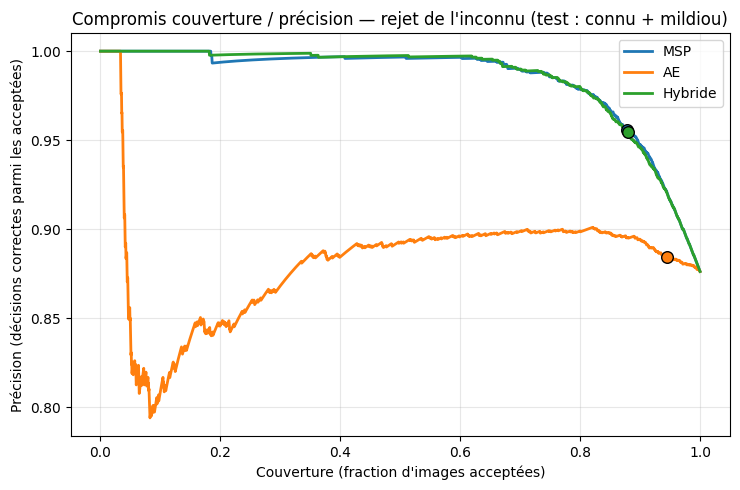

In [ ]:
import matplotlib.pyplot as plt

def couverture_precision(s_known, s_unk, pred_known, true_known):
    """Balaye le seuil : renvoie (couverture, précision) sur TOUT le test (connu + M)."""
    s_all = np.concatenate([s_known, s_unk])
    # bonne décision SI acceptée : connu bien classé -> True ; M -> False (accepté = erreur)
    bon = np.concatenate([pred_known == true_known, np.zeros(len(s_unk), dtype=bool)])
    ordre = np.argsort(s_all)                 # du MOINS suspect au PLUS suspect
    bon_tri = bon[ordre]
    N = len(s_all)
    ks = np.arange(1, N + 1)                  # on accepte les k moins suspects
    couverture = ks / N
    precision  = np.cumsum(bon_tri) / ks
    return couverture, precision

plt.figure(figsize=(7.5, 5))
for i, m in enumerate(methods):
    cov, prec = couverture_precision(sc_tk[i], sc_tu[i], pred_tk, true_tk)
    line, = plt.plot(cov, prec, label=m, lw=2)
    # point de fonctionnement = seuil calé à 5% de FRR (celui du tableau cellule 6)
    s_all = np.concatenate([sc_tk[i], sc_tu[i]])
    bon   = np.concatenate([pred_tk == true_tk, np.zeros(len(sc_tu[i]), dtype=bool)])
    acc   = s_all <= thr[m]
    plt.scatter([acc.mean()], [bon[acc].mean()], color=line.get_color(),
                s=70, edgecolor="k", zorder=5)

plt.xlabel("Couverture (fraction d'images acceptées)")
plt.ylabel("Précision (décisions correctes parmi les acceptées)")
plt.title("Compromis couverture / précision — rejet de l'inconnu (test : connu + mildiou)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(RESULTS, "p4_couverture_precision.png"), dpi=120, bbox_inches="tight")
plt.show()

## OOD proche — feuilles d'autres espèces
Premier niveau d'inconnu : des **feuilles non-tomate**. Astuce « gratuite » : les dossiers **non-Tomato** du dataset (poivron, pomme de terre) fournissent 300 images OOD réelles, échantillonnées à seed fixée.

**Interprétation :** MSP **77,7 %**, AE **19,3 %**, Hybride **80,0 %**. C'est la **MSP qui sauve** (classifieur peu confiant sur une espèce inconnue). L'AE reste faible — une feuille d'une autre plante **se reconstruit bien** (encore une feuille verte texturée). L'hybride suit la MSP (+2,3 pts).

In [ ]:
import glob

# les dossiers du dataset qui ne sont PAS de la tomate = autres espèces
ood_dirs = [d for d in sorted(os.listdir(DATA_ROOT)) if not d.startswith("Tomato")]
print("Dossiers OOD (autres espèces) :", ood_dirs)

# on échantillonne quelques dizaines d'images par dossier (seed fixée)
rng = np.random.RandomState(42)
ood_rows = []
for d in ood_dirs:
    files = sorted(glob.glob(os.path.join(DATA_ROOT, d, "*")))
    pick  = rng.choice(files, size=min(60, len(files)), replace=False)
    for f in pick:
        ood_rows.append({"path": os.path.relpath(f, DATA_ROOT), "label": "OOD_" + d})

ood_df = pd.DataFrame(ood_rows)
print("\nRépartition OOD :")
print(ood_df["label"].value_counts())
print("Total OOD :", len(ood_df))

# loader réutilisant le même DualEvalDataset (160px clf + 64px AE)
eval_ood = DataLoader(DualEvalDataset(ood_df), batch_size=64, shuffle=False, num_workers=NUM_WORKERS)

Dossiers OOD (autres espèces) : ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

Répartition OOD :
label
OOD_Pepper__bell___Bacterial_spot    60
OOD_Pepper__bell___healthy           60
OOD_Potato___Early_blight            60
OOD_Potato___Late_blight             60
OOD_Potato___healthy                 60
Name: count, dtype: int64
Total OOD : 300


In [ ]:
# signaux sur l'OOD
msp_o, pred_o, err_o, _ = deux_signaux(model, best_ae, eval_ood)
sc_o = scores(msp_o, err_o)   # [s_msp, s_ae, s_hyb] pour l'OOD

print(f"Confiance MSP moyenne sur OOD : {msp_o.mean():.3f}   (connu : {msp_vk.mean():.3f})")
print(f"Erreur AE moyenne sur OOD     : {err_o.mean():.5f} (connu : {err_vk.mean():.5f})")
print(f"(seuil veto AE tau_ae_hi = {tau_ae_hi:.5f})\n")

# taux de rejet de l'OOD, au MÊME seuil 5% FRR que p our M
print("--- Taux de rejet de l'OOD (plus haut = plus robuste) ---")
for i, m in enumerate(methods):
    taux = (sc_o[i] > thr[m]).mean()
    print(f"  {m:8s}: {taux*100:5.1f}%")

Confiance MSP moyenne sur OOD : 0.862   (connu : 0.996)
Erreur AE moyenne sur OOD     : 0.01121 (connu : 0.00772)
(seuil veto AE tau_ae_hi = 0.02011)

--- Taux de rejet de l'OOD (plus haut = plus robuste) ---
  MSP     :  77.7%
  AE      :  19.3%
  Hybride :  80.0%


## OOD lointain — 41 photos smartphone non-feuille
Niveau le plus sévère : **photos réelles** d'objets qui ne sont pas des feuilles (main, gobelet, PC, porte, mur, sandales). `DualEvalDir` lit un **dossier de chemins absolus** (au lieu de `split.csv`) et renvoie les deux versions de chaque image ; le reste du pipeline est **identique** → comparaison honnête avec l'OOD proche.

**Interprétation — et le résultat ne va PAS dans le sens attendu :** MSP **92,7 %**, AE **43,9 %**, Hybride **92,7 %**. On espérait l'AE/hybride **écrasant** la MSP sur du non-feuille. En réalité :
- la **MSP domine encore** (un objet quelconque fait chuter la confiance) ;
- l'AE **réagit plus** qu'au proche (19 → 44 %) mais reste **loin derrière** ;
- l'hybride **= MSP exactement** → le veto n'a **rien** ajouté.

**Pourquoi ?** L'erreur AE moyenne (0,0158) ne vaut que ~2× le connu et reste **sous le veto** (0,0201). L'AE note la **reconstruction pixel, aveugle à la sémantique** : une surface **lisse** (mur, main, porte) se reconstruit avec une MSE **faible**, même totalement hors-sujet. L'AE se fait avoir par ce qui est le plus « non-feuille ».

In [ ]:
import glob

OOD_DIR = os.path.join(DATA, "ood-photos")

class DualEvalDir(Dataset):
    """OOD lointain : images d'un dossier, version clf (160) + version AE (64)."""
    def __init__(self, root):
        exts = ("*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG")
        self.paths = sorted(p for e in exts for p in glob.glob(os.path.join(root, e)))
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return tf_clf_eval(img), tf_ae(img), "OOD_photo"

ds_photos = DualEvalDir(OOD_DIR)
print("Nombre de photos :", len(ds_photos))

Nombre de photos : 41


In [ ]:
eval_photos = DataLoader(ds_photos, batch_size=64, shuffle=False, num_workers=NUM_WORKERS)

# signaux sur l'OOD lointain (photos smartphone)
msp_p, pred_p, err_p, _ = deux_signaux(model, best_ae, eval_photos)
sc_p = scores(msp_p, err_p)   # [s_msp, s_ae, s_hyb]

print(f"Confiance MSP moyenne photos : {msp_p.mean():.3f}   (connu : {msp_vk.mean():.3f})")
print(f"Erreur AE moyenne photos     : {err_p.mean():.5f} (connu : {err_vk.mean():.5f})")
print(f"(seuil veto AE tau_ae_hi = {tau_ae_hi:.5f})\n")

# taux de rejet, avec les MÊMES seuils (5 % FRR sur le connu-val)
print("--- Taux de rejet de l'OOD lointain ---")
for i, m in enumerate(methods):
    taux = (sc_p[i] > thr[m]).mean()
    print(f"  {m:8s}: {taux*100:5.1f}%")

Confiance MSP moyenne photos : 0.855   (connu : 0.996)
Erreur AE moyenne photos     : 0.01584 (connu : 0.00772)
(seuil veto AE tau_ae_hi = 0.02011)

--- Taux de rejet de l'OOD lointain ---
  MSP     :  92.7%
  AE      :  43.9%
  Hybride :  92.7%


## Diagnostic par photo — qui passe le veto, et ce que ça prouve
On trie les 41 photos par erreur AE décroissante et on marque celles au-dessus du veto.

**Ce que démontrent les 13/41 au-dessus du veto :**
1. **L'erreur AE est un continuum de bas niveau**, pas un détecteur « feuille / pas feuille ». 28 photos non-feuille passent **sous** le veto (certaines à 0,001–0,005, *moins* que l'erreur moyenne des feuilles connues 0,0077). Les 13 qui dépassent sont les plus **texturées/contrastées** (écran du PC, motif des sandales).
2. **L'AE est redondant avec la MSP** : hybride = MSP = 92,7 % (38/41). Les 13 flagués étaient **déjà** rejetés par la MSP → **gain net nul**.
3. **Pire, les deux signaux échouent ensemble** : les 3 photos que la MSP accepte à tort sont **toutes sous le veto**. Là où un second avis serait utile, l'AE est muet aussi.

**Tension à exposer :** on ne peut pas baisser le veto pour attraper ces 3-là sans **re-flaguer les maladies connues** (le piège du naïf). Le p99 conservateur qui *protège* le connu est le même qui rend l'AE *inoffensif* sur l'OOD lisse.

In [ ]:
import numpy as np
noms  = [os.path.basename(p) for p in ds_photos.paths]
ordre = np.argsort(err_p)[::-1]          # du plus anormal au moins anormal

print(f"veto tau_ae_hi = {tau_ae_hi:.5f}\n")
for j in ordre:
    flag = "FLAG" if err_p[j] > tau_ae_hi else "    "
    print(f"  {flag}  err={err_p[j]:.5f}   {noms[j]}")

n_veto = int((err_p > tau_ae_hi).sum())
print(f"\nAu-dessus du veto : {n_veto}/{len(err_p)}")


veto tau_ae_hi = 0.02011

  FLAG  err=0.03859   2026_10_22_00_04_32_IMG_2139.JPG
  FLAG  err=0.03399   2026_10_22_00_08_12_IMG_2156.JPG
  FLAG  err=0.03378   2026_10_22_00_05_48_IMG_2143.JPG
  FLAG  err=0.03222   2026_10_22_00_04_39_IMG_2141.JPG
  FLAG  err=0.03045   2026_10_22_00_04_35_IMG_2140.JPG
  FLAG  err=0.02744   2026_10_22_00_09_37_IMG_2162.JPG
  FLAG  err=0.02710   2026_10_22_00_01_21_IMG_2124.JPG
  FLAG  err=0.02625   2026_10_22_00_05_46_IMG_2142.JPG
  FLAG  err=0.02289   2026_10_22_00_01_17_IMG_2123.JPG
  FLAG  err=0.02278   2026_10_22_00_01_58_IMG_2130.JPG
  FLAG  err=0.02265   2026_10_22_00_01_26_IMG_2125.JPG
  FLAG  err=0.02184   2026_10_22_00_04_10_IMG_2138.JPG
  FLAG  err=0.02098   2026_10_22_00_06_20_IMG_2145.JPG
        err=0.01976   2026_10_22_00_01_07_IMG_2121.JPG
        err=0.01831   2026_10_22_00_07_27_IMG_2150.JPG
        err=0.01648   2026_10_22_00_06_29_IMG_2147.JPG
        err=0.01585   2026_10_22_00_07_32_IMG_2152.JPG
        err=0.01576   2026_10_22_00_03_

## Cellule 9 — Récapitulatif global et figure de synthèse
On consolide : métriques de test (CSV du veto) + taux de rejet des deux OOD, et une figure unique.

**Lecture de la figure :** le **1ᵉʳ groupe** (faux rejet connu) montre que les trois méthodes paient le **même coût ~5 %** ; les groupes suivants montrent ce que ce coût **achète**. MSP et Hybride montent ensemble partout, l'AE reste écrasé dessous → AE **dominé**, hybride **= MSP sans jamais le dégrader**. Figure de soutenance : *la confiance du classifieur fait le travail ; l'AE est un filet de sécurité conservateur.*

         AUROC  rejet_M  rejet_OOD_proche  rejet_OOD_lointain  rejet_connu_FRR  acc_connu_accepte
methode                                                                                          
MSP      0.944    0.681             0.777               0.927            0.046              0.999
AE       0.562    0.119             0.193               0.439            0.047              0.995
Hybride  0.944    0.670             0.800               0.927            0.046              0.999


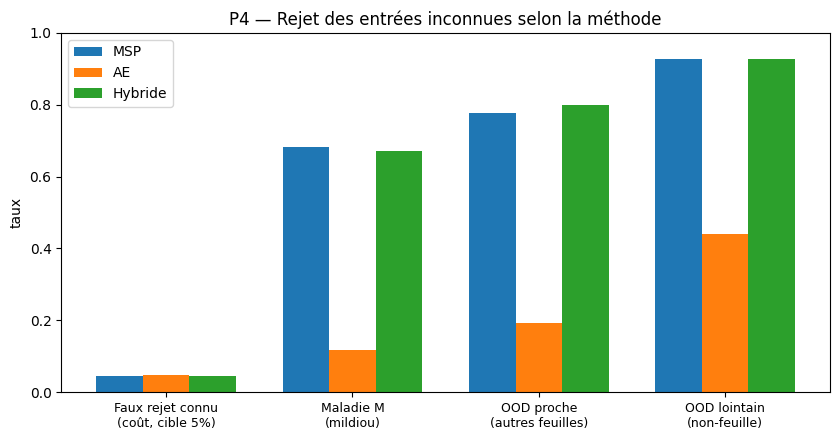

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

# --- 1. Repartir des métriques de test déjà sauvées (cellule 6) ---
recap = pd.read_csv(os.path.join(RESULTS, "p4_openset_results.csv")).set_index("methode")

# --- 2. Y greffer les taux de rejet des 2 jeux OOD (cellules 8b et 8c) ---
rej_proche   = {"MSP": 0.777, "AE": 0.193, "Hybride": 0.800}   # feuilles poivron/pomme de terre
rej_lointain = {"MSP": 0.927, "AE": 0.439, "Hybride": 0.927}   # 41 photos non-feuille
recap["rejet_OOD_proche"]   = recap.index.map(rej_proche)
recap["rejet_OOD_lointain"] = recap.index.map(rej_lointain)

recap = recap[["AUROC", "rejet_M", "rejet_OOD_proche", "rejet_OOD_lointain",
               "rejet_connu_FRR", "acc_connu_accepte"]]
print(recap.round(3).to_string())
recap.to_csv(os.path.join(RESULTS, "p4_recap_global.csv"))

# --- 3. Figure : rejet par méthode sur les 3 types d'inconnu + le coût (FRR) ---
cats   = ["rejet_connu_FRR", "rejet_M", "rejet_OOD_proche", "rejet_OOD_lointain"]
labels = ["Faux rejet connu\n(coût, cible 5%)", "Maladie M\n(mildiou)",
          "OOD proche\n(autres feuilles)", "OOD lointain\n(non-feuille)"]
methodes = ["MSP", "AE", "Hybride"]
x, w = np.arange(len(cats)), 0.25
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for i, m in enumerate(methodes):
    ax.bar(x + (i-1)*w, [recap.loc[m, c] for c in cats], w, label=m)
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("taux"); ax.set_ylim(0, 1)
ax.set_title("P4 — Rejet des entrées inconnues selon la méthode")
ax.legend(); fig.tight_layout()
fig.savefig(os.path.join(RESULTS, "p4_recap_rejet.png"), dpi=150)
plt.show()

## Conclusion de la Partie 4

**Ce qu'on retient (rapport + soutenance) :**
1. **La confiance du classifieur (MSP) est le signal de rejet universel.** Elle domine sur la maladie inconnue M *et* sur les deux régimes OOD. Contre-intuitif mais net.
2. **L'auto-encodeur est un détecteur faible et, ici, redondant.** Son erreur de reconstruction moyennée est aveugle à la sémantique : elle rate les anomalies **locales** (symptômes fins, P3) *et* les OOD **lisses** (mur, main, P4).
3. **La valeur de l'hybride n'est pas un gain de points mais la *robustesse*.** Avec le veto conservateur (p99), l'hybride **n'est jamais pire que la MSP** : filet de sécurité gratuit contre le non-feuille extrême, sans coût sur le connu.
4. **Hypothèse initiale réfutée par les données** (on attendait l'AE gagnant sur le lointain) — et c'est un **meilleur** résultat scientifique : on explique *pourquoi* un détecteur génératif par reconstruction ne complète pas un classifieur discriminatif sur ce problème.

**Recommandation de déploiement :** système **hybride MSP + veto AE** au point de fonctionnement 5 % de faux rejet (≈ 87 % de couverture, >95 % de précision), les cas rejetés routés vers un expert.

---

### Reprise du notebook sans réentraîner
1. Rejouer les cellules de **données** (setup → datasets ; `split.csv` figé + seed 42).
2. **Sauter la boucle d'entraînement.**
3. Recharger les poids : classifieur `tl_openset_best.pt` + AE `ae_k64_dn_best.pt`.
4. Rejouer la cellule des **deux signaux** (recalcule `tau_msp`, `tau_ae`) puis celle du **veto** (`tau_ae_hi` ≈ 0,0201).
5. Rejouer les cellules d'évaluation / récap. Les CSV sauvegardent les chiffres, pas les variables mémoire.

